# XY model in emu_cheb, driven by a pulser sequence

The XY (spin-exchange, hopping) model on any coupling graph,

$$
H(t) = \sum_j \frac{\Omega_j(t)}{2}\big[\cos\phi_j X_j + \sin\phi_j Y_j\big] - \sum_j \Delta_j(t)\, n_j
 + \sum_{i<j} \frac{J_{ij}}{2} \big( X_iX_j + Y_iY_j \big),
\qquad \frac{1}{2}(X_iX_j + Y_iY_j) = \sigma^+_i\sigma^-_j + \sigma^-_i\sigma^+_j ,
$$

run by `emu_cheb.ChebBackend` and checked against exact dense simulations (4 atoms). Frequencies in rad/µs, times in
ns, $n = |1\rangle\langle 1| = (1-Z)/2$, atom 0 = most significant bit of the basis index. Two ways to set it up:

1. **pulser's XY channel** (`mw_global`) with **any coupling matrix**: `ChebConfig(interaction_matrix=...)`. In XY
   mode pulser / emu-base take a 2-layer stack `[J_XY, C6]`: the first layer gives $\frac{J_{ij}}{2}(X_iX_j+Y_iY_j)$,
   the second a $C_6^{ij}|uu\rangle\langle uu|$ shift (zero for the pure XY model). Without `interaction_matrix`
   pulser uses the dipolar couplings $C_3(1-3\cos^2\theta_{ij})/r_{ij}^3$ and the $C_6/r^6$ shift of the register.
2. **the Heisenberg stack**: `ChebConfig(heisenberg=[J/2, J/2, 0])`, i.e. $J^{xx} = J^{yy} = J/2$, $J^{zz} = 0$
   (works for any sequence; also gives XXZ models with $J^{zz} \neq 0$).

Both are the same Hamiltonian; below they agree to round-off with each other and with the exact evolution.

In [1]:
import logging
import time
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pulser
import torch
from pulser.devices import MockDevice

from emu_base import PulserData
from emu_cheb import ChebBackend, ChebConfig, CorrelationMatrix, Energy, Occupation, StateResult, StateVector, connected

dtype = torch.complex128

## 1. Register, couplings and sequences

Four atoms on a square (the geometry only matters for pulser's default couplings). The custom couplings are a ring
with unequal bonds plus one diagonal: a graph no geometry would give. Two sequences on the global microwave channel:
- **pulsed**: Blackman π-pulse with a detuning ramp from -3 to 3 rad/µs, from the Néel state $|0101\rangle$;
- **free**: no drive, from one excitation $|1000\rangle$: pure hopping, the excitation spreads over the graph.

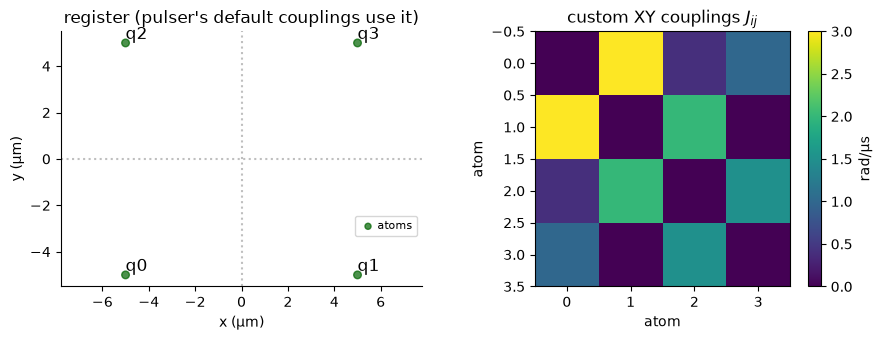

In [2]:
n, T, dt = 4, 1000, 10  # atoms, duration (ns), drive sampling step (ns)
reg = pulser.Register.square(2, spacing=10.0, prefix="q")

J = np.array([[0.0, 3.0, 0.4, 1.0],   # custom XY couplings J_ij (rad/us): ring 0-1-2-3 with unequal bonds,
              [3.0, 0.0, 2.0, 0.0],   # one diagonal (0-2), the other (1-3) absent
              [0.4, 2.0, 0.0, 1.5],
              [1.0, 0.0, 1.5, 0.0]])


def make_sequence(pulsed):
    seq = pulser.Sequence(reg, MockDevice)
    seq.declare_channel("mw", "mw_global")
    if pulsed:
        seq.add(pulser.Pulse(pulser.BlackmanWaveform(T, np.pi), pulser.RampWaveform(T, -3.0, 3.0), 0.0), "mw")
    else:
        seq.delay(T, "mw")
    return seq


cases = {  # name: (sequence, initial bitstring)
    "pulsed": (make_sequence(True), "0101"),
    "free": (make_sequence(False), "1000"),
}
times = [k / 50 for k in range(51)]  # every 20 ns, as fractions of T
rows = [round(t * T / dt) for t in times]  # their index on the dt grid of the exact references


def basis_state(bits):
    psi = torch.zeros(2**n, dtype=dtype)
    psi[int(bits, 2)] = 1.0
    return StateVector(psi, gpu=False)


fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
reg.draw(custom_ax=axes[0], show=False)
axes[0].set_title("register (pulser's default couplings use it)")
fig.colorbar(axes[1].imshow(J, cmap="viridis"), ax=axes[1], label="rad/µs")
axes[1].set_title("custom XY couplings $J_{ij}$"); axes[1].set_xlabel("atom"); axes[1].set_ylabel("atom")
fig.tight_layout()

## 2. Exact references

Dense $2^4$ simulations driven by the very same `SequenceData` arrays as emu_cheb (`PulserData` samples:
`omega[k]`, `delta[k]`, `phi[k]` constant on `[target_times[k], target_times[k+1]]`), with the interaction written
out from Pauli matrices: $\frac{J_{ij}}{2}(X_iX_j + Y_iY_j)$ plus, for pulser's default couplings, the
$C_6^{ij} |u\rangle\langle u|_i |u\rangle\langle u|_j$ shift ($|u\rangle$ = index 0).

In [3]:
X = torch.tensor([[0, 1], [1, 0]], dtype=dtype)
Y = torch.tensor([[0, -1j], [1j, 0]], dtype=dtype)
Nd = torch.tensor([[0, 0], [0, 1]], dtype=dtype)
Pu = torch.tensor([[1, 0], [0, 0]], dtype=dtype)  # |u><u|, index 0


def op(single, i):
    return reduce(torch.kron, [single if k == i else torch.eye(2, dtype=dtype) for k in range(n)])


N_ops = [op(Nd, j) for j in range(n)]
pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]


def interaction(J_xy, C6=None):
    H = sum(J_xy[i, j] / 2 * (op(X, i) @ op(X, j) + op(Y, i) @ op(Y, j)) for i, j in pairs)
    if C6 is not None:
        H = H + sum(C6[i, j] * op(Pu, i) @ op(Pu, j) for i, j in pairs)
    return H


def hamiltonians(sd, H_int):
    w, d, p = sd.omega.real, sd.delta.real, sd.phi.real
    return [H_int + sum(w[k, j] / 2 * (torch.cos(p[k, j]) * op(X, j) + torch.sin(p[k, j]) * op(Y, j))
                        - d[k, j] * N_ops[j] for j in range(n)) for k in range(len(w))]


def exact_state_dynamics(sd, H_int, bits):
    # occupations, <n_i n_j> and energies <H_k> (H of the step ending at each grid time) on the dt grid
    Hs = hamiltonians(sd, H_int)
    psi = basis_state(bits).data.clone()
    out = {"occ": [], "corr": [], "energy": []}

    def record(H):
        out["occ"].append(torch.stack([torch.vdot(psi, Nj @ psi).real for Nj in N_ops]))
        out["corr"].append(torch.stack([torch.stack([torch.vdot(psi, Ni @ Nj @ psi).real for Nj in N_ops]) for Ni in N_ops]))
        out["energy"].append(torch.vdot(psi, H @ psi).real)

    record(Hs[0])
    for H, t0, t1 in zip(Hs, sd.target_times, sd.target_times[1:]):
        psi = torch.linalg.matrix_exp(-1j * H * (t1 - t0) / 1000) @ psi  # µs
        record(H)
    return {k: torch.stack(v) for k, v in out.items()}


def exact_lindblad_dynamics(sd, H_int, bits, n_sub=10):
    # RK4 on rho' = -i[H, rho] + sum_k L rho L^+ - 1/2 {L^+ L, rho}
    Ls = [op(L, j) for L in sd.lindblad_ops for j in range(n)]
    LdL = sum(L.mH @ L for L in Ls)

    def rhs(rho, H_eff):
        out = -1j * (H_eff @ rho - rho @ H_eff.mH)
        for L in Ls:
            out += L @ rho @ L.mH
        return out

    rho = torch.zeros(2**n, 2**n, dtype=dtype)
    rho[int(bits, 2), int(bits, 2)] = 1.0
    occ = [torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops])]
    for H, t0, t1 in zip(hamiltonians(sd, H_int), sd.target_times, sd.target_times[1:]):
        H_eff, h = H - 0.5j * LdL, (t1 - t0) / 1000 / n_sub
        for _ in range(n_sub):
            k1 = rhs(rho, H_eff)
            k2 = rhs(rho + h / 2 * k1, H_eff)
            k3 = rhs(rho + h / 2 * k2, H_eff)
            k4 = rhs(rho + h * k3, H_eff)
            rho = rho + h / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        occ.append(torch.stack([torch.trace(Nj @ rho).real for Nj in N_ops]))
    return torch.stack(occ)

## 3. emu_cheb vs exact: three ways to an XY Hamiltonian

- **custom (pulser XY)**: `interaction_matrix = [J, 0]`;
- **custom (Heisenberg stack)**: `heisenberg = [J/2, J/2, 0]`;
- **pulser default**: no `interaction_matrix`: dipolar $C_3$ couplings of the square plus the $C_6$ shift.

Observables: `Occupation`, `CorrelationMatrix` (for the connected correlator) and `Energy`, at every 20 ns.

In [4]:
zeros = np.zeros((n, n))
routes = {
    "custom (pulser XY)": dict(interaction_matrix=np.stack([J, zeros])),
    "custom (Heisenberg stack)": dict(heisenberg=np.stack([J / 2, J / 2, zeros])),
    "pulser default": dict(),
}


def run_cheb(seq, bits, extra, noise_model=None, n_traj=1, observables=None):
    observables = observables or [Occupation(evaluation_times=times), CorrelationMatrix(evaluation_times=times),
                                  Energy(evaluation_times=times)]
    config = ChebConfig(observables=observables, initial_state=basis_state(bits), noise_model=noise_model,
                        n_trajectories=n_traj, dt=dt, log_level=logging.WARN, **extra)
    backend = ChebBackend(seq, config=config)
    t0 = time.perf_counter()
    results = backend.run()
    return results, backend, time.perf_counter() - t0


def exact_interaction(seq, extra):
    if extra:  # the custom couplings, either route
        return interaction(J)
    (sd,) = PulserData(sequence=seq, config=ChebConfig(dt=dt), dt=dt).get_sequences()
    C3, C6 = sd.interaction_matrix(0.0)  # pulser's default XY stack
    return interaction(C3, C6)


exact, cheb = {}, {}
for case, (seq, bits) in cases.items():
    (sd,) = PulserData(sequence=seq, config=ChebConfig(dt=dt), dt=dt).get_sequences()
    for route, extra in routes.items():
        ref = exact_state_dynamics(sd, exact_interaction(seq, extra), bits)
        exact[case, route] = {k: v[rows] for k, v in ref.items()}
        results, backend, seconds = run_cheb(seq, bits, extra)
        cheb[case, route] = {"occ": torch.stack(results.occupation), "corr": torch.stack(results.correlation_matrix),
                             "energy": torch.stack(results.energy)}
        err = {k: float((cheb[case, route][k] - exact[case, route][k]).abs().max()) for k in ("occ", "corr", "energy")}
        print(f"{case:>6} | {route:26s}: max error <n_i> {err['occ']:.1e}, <n_i n_j> {err['corr']:.1e}, "
              f"<H> {err['energy']:.1e}; {backend.raw.stats['optimization']}, {seconds:.2f} s")

d = max(float((cheb[c, "custom (pulser XY)"]["occ"] - cheb[c, "custom (Heisenberg stack)"]["occ"]).abs().max()) for c in cases)
print(f"pulser XY route vs Heisenberg-stack route: max |d<n_i>| = {d:.1e}")

/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/config.py:85: UserWarning: 'ChebConfig' was initialized without any observables. The corresponding emulation results will be empty.
  super().__init__(
/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/solvers/rydberg_cheb_fast.py:448: UserWarning: long double is float64 here: Bessel coefficients accurate to ~4e-14 and global phase to ~1e-13 only (amplitudes ~1e-13)
  bessel = _bessel(alphas, rho)


pulsed | custom (pulser XY)        : max error <n_i> 9.9e-15, <n_i n_j> 9.9e-15, <H> 6.9e-14; turbo, 0.16 s


pulsed | custom (Heisenberg stack) : max error <n_i> 9.8e-15, <n_i n_j> 9.8e-15, <H> 6.6e-14; turbo, 0.16 s


pulsed | pulser default            : max error <n_i> 5.7e-15, <n_i n_j> 6.2e-15, <H> 1.7e-13; turbo, 0.45 s
  free | custom (pulser XY)        : max error <n_i> 1.2e-14, <n_i n_j> 1.2e-14, <H> 6.1e-15; turbo, 0.08 s


  free | custom (Heisenberg stack) : max error <n_i> 1.2e-14, <n_i n_j> 1.2e-14, <H> 5.3e-15; turbo, 0.06 s
  free | pulser default            : max error <n_i> 5.8e-14, <n_i n_j> 5.8e-14, <H> 1.4e-12; turbo, 0.12 s
pulser XY route vs Heisenberg-stack route: max |d<n_i>| = 1.6e-15


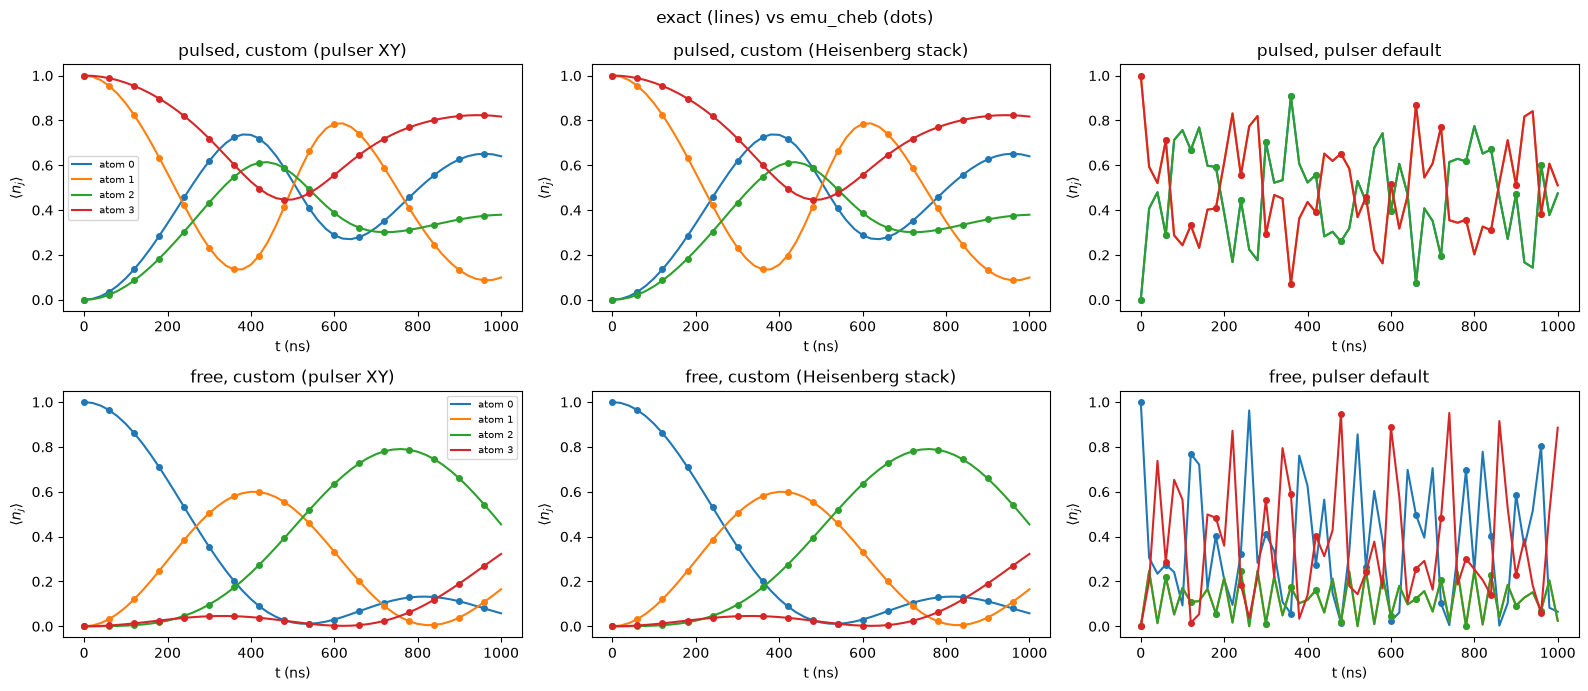

In [5]:
tt = np.array(times) * T
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for row, case in zip(axes, cases):
    for ax, route in zip(row, routes):
        for j in range(n):
            (line,) = ax.plot(tt, exact[case, route]["occ"][:, j], label=f"atom {j}")
            ax.plot(tt[::3], cheb[case, route]["occ"][::3, j], "o", color=line.get_color(), ms=4)
        ax.set_title(f"{case}, {route}"); ax.set_xlabel("t (ns)"); ax.set_ylabel(r"$\langle n_j \rangle$")
    row[0].legend(fontsize=7)
fig.suptitle("exact (lines) vs emu_cheb (dots)")
fig.tight_layout()

**Free hopping.** Without drive the XY Hamiltonian conserves the number of excitations: from $|1000\rangle$ the
total $\sum_i\langle n_i\rangle$ stays 1 while the excitation spreads along the strong bonds (0-1, 1-2, 2-3) and
leaks through the weak diagonal. The connected correlator $\langle n_in_j\rangle - \langle n_i\rangle\langle n_j\rangle$
of a single excitation is $-\langle n_i\rangle\langle n_j\rangle$ off the diagonal (it is never on two atoms at once).

free hopping: max |sum_i <n_i> - 1| = 2.2e-16
connected correlator at 500 ns: max |emu_cheb - exact| = 6.2e-15


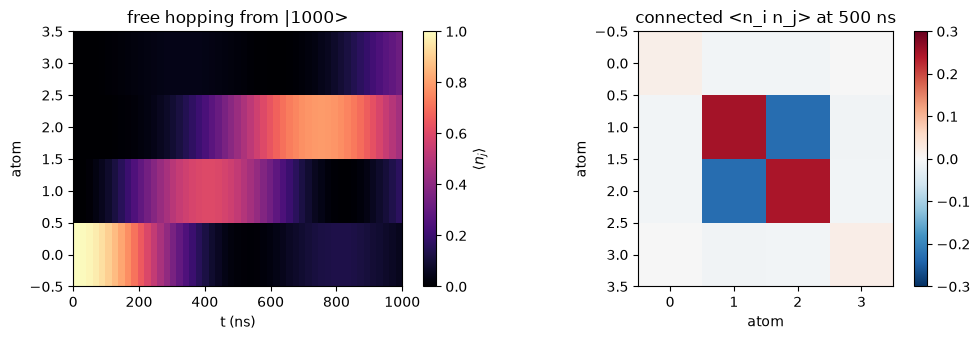

In [6]:
c = cheb["free", "custom (pulser XY)"]
print(f"free hopping: max |sum_i <n_i> - 1| = {float((c['occ'].sum(1) - 1).abs().max()):.1e}")
k = len(times) // 2
C = connected(c["occ"][k], c["corr"][k])
C_exact = connected(exact["free", "custom (pulser XY)"]["occ"][k], exact["free", "custom (pulser XY)"]["corr"][k])
print(f"connected correlator at {tt[k]:.0f} ns: max |emu_cheb - exact| = {float((C - C_exact).abs().max()):.1e}")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
im = axes[0].imshow(c["occ"].T, aspect="auto", origin="lower", extent=(0, T, -0.5, n - 0.5), cmap="magma", vmin=0, vmax=1)
fig.colorbar(im, ax=axes[0], label=r"$\langle n_j \rangle$")
axes[0].set_title("free hopping from |1000>"); axes[0].set_xlabel("t (ns)"); axes[0].set_ylabel("atom")
fig.colorbar(axes[1].imshow(C, cmap="RdBu_r", vmin=-0.3, vmax=0.3), ax=axes[1])
axes[1].set_title(f"connected <n_i n_j> at {tt[k]:.0f} ns"); axes[1].set_xlabel("atom"); axes[1].set_ylabel("atom")
fig.tight_layout()

## 4. Every engine

The XY model is only an interaction matrix, so every engine of `emu_cheb.solvers` runs it unchanged:
`optimization="reference" | "fast" | "turbo"` (any drive, any noise) and `"quench"` (noiseless constant drive from the
ground state: `heisenberg_cheb_fast`, with pulser's XY stack mapped exactly onto a Heisenberg one,
$J^{xx} = J^{yy} = C_3/2$, $J^{zz} = C_6/4$, $\delta_i \to \delta_i + \sum_j C_6^{ij}/2$, up to a global phase).
`"auto"` picks `"quench"` here. A constant drive from $|0000\rangle$, custom couplings with a non-zero $C_6$ layer and
pulser's default stack:

In [7]:
quench_seq = pulser.Sequence(reg, MockDevice)
quench_seq.declare_channel("mw", "mw_global")
quench_seq.add(pulser.Pulse.ConstantPulse(T, 3.0, 1.0, 0.0), "mw")
C6_custom = 0.7 * (J > 1)  # a C6 shift on the strong bonds, to exercise the mapping
stacks = {"custom [J, C6]": dict(interaction_matrix=np.stack([J, C6_custom])), "pulser default": dict()}
optimizations = ["reference", "fast", "turbo", "quench", "auto"]

for label, extra in stacks.items():
    config = ChebConfig(dt=dt, **extra)
    (sd,) = PulserData(sequence=quench_seq, config=config, dt=dt).get_sequences()
    C3, C6 = sd.interaction_matrix(0.0)
    target = exact_state_dynamics(sd, interaction(C3, C6), "0000")["occ"][rows]
    for opt in optimizations:
        config = ChebConfig(observables=[Occupation(evaluation_times=times)], optimization=opt, dt=dt,
                            log_level=logging.WARN, **extra)
        backend = ChebBackend(quench_seq, config=config)
        backend.run()  # first call: warm-up (caches, kernels)
        t0 = time.perf_counter()
        occ = torch.stack(backend.run().occupation)
        seconds = time.perf_counter() - t0
        print(f"{label:15s} optimization={opt:9s} -> {backend.raw.stats['optimization']:9s}: "
              f"max |<n_i> - exact| {float((occ - target).abs().max()):.1e}, {1000 * seconds:7.1f} ms")

/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/config.py:85: UserWarning: 'ChebConfig' was initialized without any observables. The corresponding emulation results will be empty.
  super().__init__(
/Users/i.sokolov/Code/emulators/ci/emu_cheb/emu_cheb/solvers/rydberg_cheb_fast.py:448: UserWarning: long double is float64 here: Bessel coefficients accurate to ~4e-14 and global phase to ~1e-13 only (amplitudes ~1e-13)
  bessel = _bessel(alphas, rho)


custom [J, C6]  optimization=reference -> reference: max |<n_i> - exact| 2.1e-15,    83.9 ms
custom [J, C6]  optimization=fast      -> fast     : max |<n_i> - exact| 2.0e-15,    58.1 ms


custom [J, C6]  optimization=turbo     -> turbo    : max |<n_i> - exact| 1.8e-15,    59.9 ms
custom [J, C6]  optimization=quench    -> quench   : max |<n_i> - exact| 2.0e-15,    17.1 ms
custom [J, C6]  optimization=auto      -> quench   : max |<n_i> - exact| 2.0e-15,    17.3 ms


pulser default  optimization=reference -> reference: max |<n_i> - exact| 1.1e-16,   162.8 ms


pulser default  optimization=fast      -> fast     : max |<n_i> - exact| 1.1e-16,   123.7 ms


pulser default  optimization=turbo     -> turbo    : max |<n_i> - exact| 1.2e-16,   104.9 ms
pulser default  optimization=quench    -> quench   : max |<n_i> - exact| 1.1e-16,    39.0 ms
pulser default  optimization=auto      -> quench   : max |<n_i> - exact| 1.1e-16,    36.2 ms


With noise, the trajectory engines (the quench solvers are noiseless): the custom XY model, pulsed case, dephasing and
depolarizing, against the exact Lindblad equation (500 trajectories for fast / turbo, 200 for the slower reference).
`fast` and `turbo` give the same trajectories for the same seed (one random stream per trajectory); `reference` draws
all trajectories from one stream, so it agrees statistically. The standard errors use the per-trajectory spread of a
separate 4000-trajectory turbo run: early on almost no trajectory has jumped yet, and a small sample's own spread
underestimates the error there (z would be meaningless).

In [8]:
noise_model = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)  # 1/µs
seq, bits = cases["pulsed"]
(sd,) = PulserData(sequence=seq, config=ChebConfig(dt=dt, noise_model=noise_model), dt=dt).get_sequences()
target = exact_lindblad_dynamics(sd, interaction(J), bits)[rows]
def noisy_run(opt, n_traj, seed):
    config = ChebConfig(observables=[Occupation(evaluation_times=times)], initial_state=basis_state(bits),
                        noise_model=noise_model, n_trajectories=n_traj, optimization=opt, seed=seed, dt=dt,
                        log_level=logging.WARN, **routes["custom (pulser XY)"])
    backend = ChebBackend(seq, config=config)
    t0 = time.perf_counter()
    occ = torch.stack(backend.run().occupation)
    return occ, backend, time.perf_counter() - t0


spread = noisy_run("turbo", 4000, seed=99)[1].raw.occupations.std(0)  # per-trajectory spread (separate sample)
occ_engines = {}
for opt, n_traj_engine in [("reference", 200), ("fast", 500), ("turbo", 500)]:
    occ_engines[opt], backend, seconds = noisy_run(opt, n_traj_engine, seed=1)
    z = ((occ_engines[opt] - target).abs() / (spread / n_traj_engine**0.5).clamp_min(1e-12))[1:]
    print(f"{opt:9s}: max |MC - Lindblad| {float((occ_engines[opt] - target).abs().max()):.4f} "
          f"(max z {float(z.max()):.1f} over {z.numel()} values), {n_traj_engine} trajectories in {seconds:.2f} s")
print(f"fast vs turbo, trajectory for trajectory: max |d<n_i>| = {float((occ_engines['fast'] - occ_engines['turbo']).abs().max()):.1e}")

reference: max |MC - Lindblad| 0.0248 (max z 2.3 over 200 values), 200 trajectories in 39.66 s


fast     : max |MC - Lindblad| 0.0073 (max z 1.9 over 200 values), 500 trajectories in 0.88 s


turbo    : max |MC - Lindblad| 0.0073 (max z 1.9 over 200 values), 500 trajectories in 0.86 s
fast vs turbo, trajectory for trajectory: max |d<n_i>| = 0.0e+00


## 5. With noise

A pulser `NoiseModel` (dephasing and depolarizing) on the custom XY model. emu_cheb averages `n_traj` exact quantum
trajectories in one call (emu-mps' noise model); the error bars come from the per-trajectory occupations
(`backend.raw`). Target: the exact Lindblad equation.

pulsed: max |MC - Lindblad| 0.0043 (std. error up to 0.0047, max z 1.9); noise effect 0.128; 2000 trajectories in 2.3 s


  free: max |MC - Lindblad| 0.0073 (std. error up to 0.0054, max z 2.1); noise effect 0.128; 2000 trajectories in 1.1 s


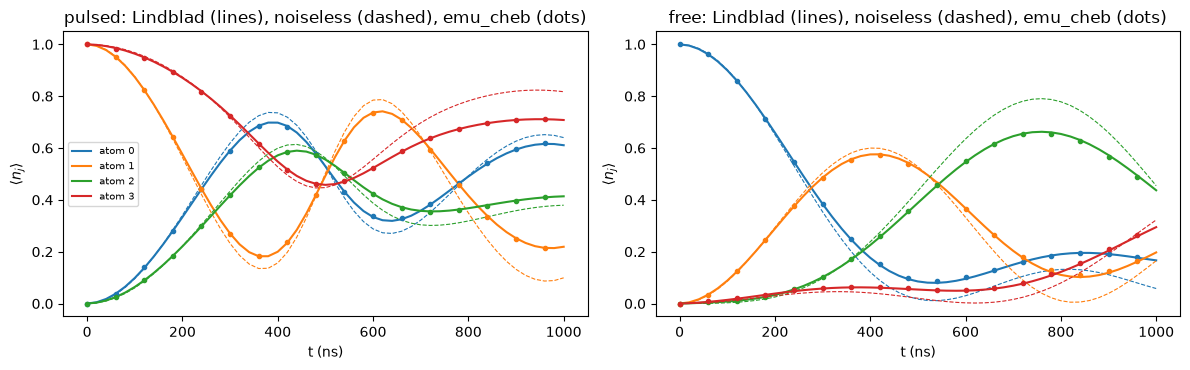

In [9]:
noise_model = pulser.NoiseModel(dephasing_rate=0.2, depolarizing_rate=0.1)  # 1/µs
n_traj = 2000
noisy = {}
for case, (seq, bits) in cases.items():
    extra = routes["custom (pulser XY)"]
    results, backend, seconds = run_cheb(seq, bits, extra, noise_model, n_traj, [Occupation(evaluation_times=times)])
    (sd,) = PulserData(sequence=seq, config=ChebConfig(dt=dt, noise_model=noise_model), dt=dt).get_sequences()
    target = exact_lindblad_dynamics(sd, interaction(J), bits)[rows]
    mc = torch.stack(results.occupation)
    err = backend.raw.occupations.std(0) / n_traj**0.5
    z = ((mc - target).abs() / err.clamp_min(1e-12))[1:]
    noisy[case] = dict(mc=mc, err=err, target=target)
    print(f"{case:>6}: max |MC - Lindblad| {float((mc - target).abs().max()):.4f} (std. error up to {float(err.max()):.4f}, "
          f"max z {float(z.max()):.1f}); noise effect {float((target - exact[case, 'custom (pulser XY)']['occ']).abs().max()):.3f}; "
          f"{n_traj} trajectories in {seconds:.1f} s")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, case in zip(axes, cases):
    r = noisy[case]
    for j in range(n):
        (line,) = ax.plot(tt, r["target"][:, j], label=f"atom {j}")
        ax.plot(tt, exact[case, "custom (pulser XY)"]["occ"][:, j], "--", color=line.get_color(), lw=0.8)
        ax.errorbar(tt[::3], r["mc"][::3, j], yerr=r["err"][::3, j], fmt="o", color=line.get_color(), ms=3)
    ax.set_title(f"{case}: Lindblad (lines), noiseless (dashed), emu_cheb (dots)")
    ax.set_xlabel("t (ns)"); ax.set_ylabel(r"$\langle n_j \rangle$")
axes[0].legend(fontsize=7)
fig.tight_layout()

**Summary.** The XY model needs nothing beyond pulser's own interface, and every engine runs it: on the XY channel a custom
`interaction_matrix` stack `[J, C6]` gives any coupling graph (and `[J, 0]` the pure XY model), and the
Heisenberg stack `[J/2, J/2, Jzz]` gives the same model or XXZ variants. emu_cheb agrees with the exact evolution to
round-off for occupations, correlations and energies, and with the exact Lindblad equation within statistical error
under noise. See `emu_cheb/README.md` ("Hamiltonians") for the conventions.